<a href="https://colab.research.google.com/github/Nihat0311/Machine-Learning/blob/main/Decision_Tree.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeRegressor, plot_tree
from sklearn.metrics import mean_squared_error, r2_score

from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.ensemble import RandomForestRegressor


from sklearn.datasets import load_iris

from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

In [ ]:
iris = load_iris()
X=iris.data
y=iris.target

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X,y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [ ]:
model=DecisionTreeClassifier(
    max_depth=15,
    random_state=42
)
model.fit(X_train,y_train)

DecisionTreeClassifier(max_depth=15, random_state=42)

In [ ]:
model.score(X_train,y_train)

1.0

In [ ]:
model.score(X_test,y_test)

0.9333333333333333

In [ ]:
y_pred=model.predict(X_test)

Text(0.5, 1.0, 'Confusion Matrix')

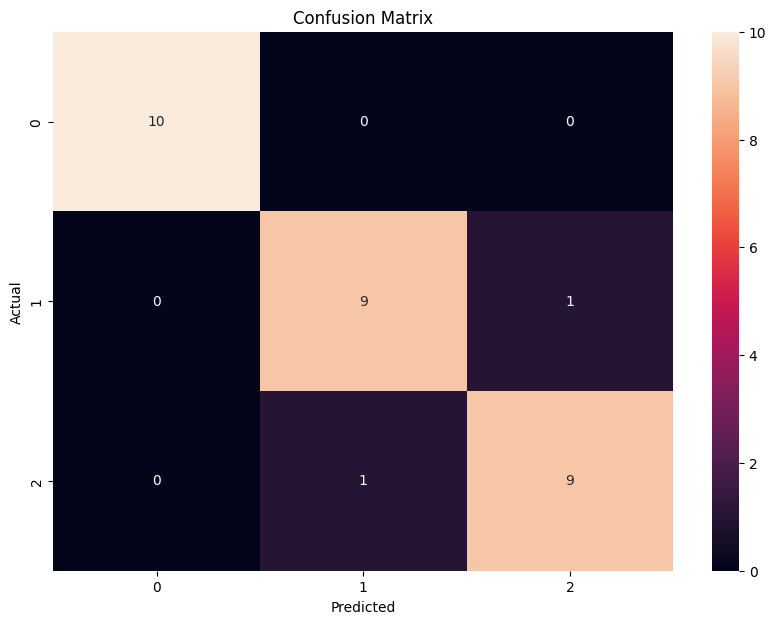

In [ ]:
cm=confusion_matrix(y_test,y_pred)
plt.figure(figsize=(10,7))
sns.heatmap(cm,annot=True,fmt='d')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix')


In [ ]:
data=load_iris(as_frame=True)
df=data['data']
df

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
0,5.1,3.5,1.4,0.2
1,4.9,3.0,1.4,0.2
2,4.7,3.2,1.3,0.2
3,4.6,3.1,1.5,0.2
4,5.0,3.6,1.4,0.2
...,...,...,...,...
145,6.7,3.0,5.2,2.3
146,6.3,2.5,5.0,1.9
147,6.5,3.0,5.2,2.0
148,6.2,3.4,5.4,2.3


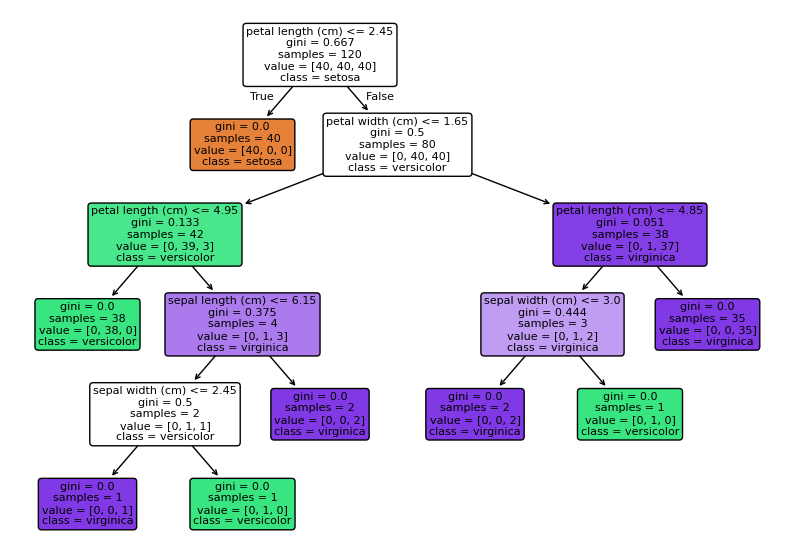

In [ ]:
plt.figure(figsize=(10,7))
plot_tree(model,feature_names=iris.feature_names,class_names=iris.target_names,filled=True,rounded=True)
plt.show()

In [ ]:
!curl -L -o california-housing-prices.zip\
  https://www.kaggle.com/api/v1/datasets/download/camnugent/california-housing-prices

  % Total    % Received % Xferd  Average Speed   Time    Time     Time  Current
                                 Dload  Upload   Total   Spent    Left  Speed
  0     0    0     0    0     0      0      0 --:--:-- --:--:-- --:--:--     0
100  399k  100  399k    0     0   312k      0  0:00:01  0:00:01 --:--:--  864k


In [ ]:
!unzip /content/california-housing-prices.zip

Archive:  /content/california-housing-prices.zip
replace housing.csv? [y]es, [n]o, [A]ll, [N]one, [r]ename: 

In [ ]:
df=pd.read_csv('/content/housing.csv')
df

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,NEAR BAY
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,NEAR BAY
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,NEAR BAY
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,NEAR BAY
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,NEAR BAY
...,...,...,...,...,...,...,...,...,...,...
20635,-121.09,39.48,25.0,1665.0,374.0,845.0,330.0,1.5603,78100.0,INLAND
20636,-121.21,39.49,18.0,697.0,150.0,356.0,114.0,2.5568,77100.0,INLAND
20637,-121.22,39.43,17.0,2254.0,485.0,1007.0,433.0,1.7000,92300.0,INLAND
20638,-121.32,39.43,18.0,1860.0,409.0,741.0,349.0,1.8672,84700.0,INLAND


In [ ]:
X=df.drop('median_house_value',axis=1)
y=df['median_house_value'].copy()

In [ ]:
X_train,X_test,y_train,y_test=train_test_split(
    X,y,
    test_size=0.2,
    random_state=42
)

In [ ]:
num_features=X_train.select_dtypes(include=np.number).columns
cat_features=X_train.select_dtypes(exclude=np.number).columns

In [ ]:
num_pipeline=Pipeline([
    ('imputer',SimpleImputer(strategy='median')),
])
cat_pipeline=Pipeline([
    ('imputer',SimpleImputer(strategy='most_frequent')),
    ('onehot',OneHotEncoder(handle_unknown='ignore'))
])
transformer=ColumnTransformer([
    ('num',num_pipeline,num_features),
    ('cat',cat_pipeline,cat_features)
])
model=DecisionTreeRegressor(
    max_depth=10,
    min_samples_split=30,
    min_samples_leaf=55,
    random_state=42
)
full_pipeline=Pipeline([
    ('transformer',transformer),
    ('estimator',model)
])
full_pipeline.fit(X_train,y_train)

Pipeline(steps=[('transformer',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median'))]),
                                                  Index(['longitude', 'latitude', 'housing_median_age', 'total_rooms',
       'total_bedrooms', 'population', 'households', 'median_income'],
      dtype='object')),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('onehot',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  Index(['ocean_proximity'], dtype='object'))])),
                ('estimator',
                 DecisionTreeRegressor(max_depth=10, min_samples_leaf=55,
                                       min_samples_split=30,
                                       random_state=42))])

In [ ]:
full_pipeline.score(X_train,y_train)

0.7445668418025575

In [ ]:
full_pipeline.score(X_test,y_test)

0.7126391511224568

In [ ]:
r2=r2_score(y_test,full_pipeline.predict(X_test))
print(r2)
mse=mean_squared_error(y_test,full_pipeline.predict(X_test))
print(mse)
mae=mean_absolute_error(y_test,full_pipeline.predict(X_test))
print(mae)
rsme=np.sqrt(mse)
print(rsme)
resd=np.sqrt(rsme)
print(resd)

0.7126391511224568
3765602363.640591
41394.64596618272
61364.50410164325
247.71859861876186
